# 📄 Semantic Resume & Job Matcher
## Module 01: Raw Dataset Exploration & NLP Preprocessing Pipeline

---

### 🎯 Objective
This notebook performs an exhaustive end-to-end data audit, exploratory data analysis (EDA), anomaly diagnostics, and text preprocessing on the raw job descriptions dataset (`data/raw/data.csv`). 

### 🏗️ Why Preprocessing is Mission-Critical for Semantic Matching:
1. **Transformer Token Limits:** The target embedding model (`sentence-transformers/all-MiniLM-L6-v2`) has a maximum context length of **256 tokens** (~180-200 words). Raw job descriptions in this dataset average **650 words** (some exceeding 2,100 words). Unprocessed text causes **over 60% of technical qualifications to be silently truncated**.
2. **Boilerplate Noise:** Over **58%** of postings contain Equal Employment Opportunity (EEO) legal disclaimers, and **59%** contain 401(k)/dental/vision benefits paragraphs. Embedding these dilutes the semantic representations of actual candidate requirements.
3. **Unicode Ligature Corruption:** The raw data contains non-ASCII typographic ligatures (e.g., `\ufb01` for "fi" in words like `bene\ufb01ts`, `pro\ufb01t`, `e\ufb03cient`). Without NFKD Unicode normalization, transformer tokenizers treat these as out-of-vocabulary (`[UNK]`) tokens.
4. **Data Degradation & Outliers:** Degenerate listings (e.g. Row 18: `"na"`, Row 248: 9-word location snippet) must be flagged and removed.

---

### 📊 Pipeline Workflow
```
[Raw CSVs] 
    │
    ▼
[Step 1: Ingestion & Integrity Audit] ──► Duplicate check (data.csv vs data_01.csv)
    │
    ▼
[Step 2: Anomaly & Outlier Detection] ──► Identify placeholders, short stubs & French listings
    │
    ▼
[Step 3: Unicode & Ligature Normalization] ──► NFKD decomposition (fix ﬁ, ﬂ, œ)
    │
    ▼
[Step 4: Boilerplate & Noise Stripping] ──► Regex removal of EEO, Benefits & URLs
    │
    ▼
[Step 5: Skill Extraction & Categorization] ──► High-precision taxonomy matching
    │
    ▼
[Step 6: Semantic Chunking] ──► Overlapping windows & dense profile generation (≤ 256 tokens)
    │
    ▼
[Step 7: Clean Data Export] ──► data/processed/ (cleaned jobs, skills, semantic chunks)
```


In [1]:
# Standard Library Imports
import os
import re
import sys
import html
import unicodedata
from pathlib import Path

# Data Manipulation & Numerical
import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Styling & Display
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['font.size'] = 11

print("Environment libraries loaded successfully.")
print(f"Pandas Version: {pd.__version__}")


Environment libraries loaded successfully.
Pandas Version: 2.3.3


---
## Step 1: Ingestion & Integrity Audit

We inspect the raw data files stored in `data/raw/`:
- `data/raw/data.csv`
- `data/raw/data_01.csv`

We check file checksums, record counts, null values, and column schemas.


In [2]:
# Define paths
RAW_DIR = Path('../data/raw')
PROCESSED_DIR = Path('../data/processed')
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

raw_data_path = RAW_DIR / 'data.csv'
raw_data01_path = RAW_DIR / 'data_01.csv'

# Check file existence
assert raw_data_path.exists(), f"Missing file: {raw_data_path}"
assert raw_data01_path.exists(), f"Missing file: {raw_data01_path}"

# Check byte-level equality
import filecmp
is_identical = filecmp.cmp(raw_data_path, raw_data01_path, shallow=False)
print(f"data.csv and data_01.csv are identical: {is_identical}")

# Load primary dataset
df_raw = pd.read_csv(raw_data_path)
print(f"\nLoaded Dataset Shape: {df_raw.shape[0]} rows, {df_raw.shape[1]} columns")
print(f"Columns: {list(df_raw.columns)}")
df_raw.head()


data.csv and data_01.csv are identical: True

Loaded Dataset Shape: 521 rows, 2 columns
Columns: ['Job Title', 'Description']


,Job Title,Description
0,Data Analyst,job overview were seeking a data analyst to tu...
1,Data Reporting Analyst,about wspc wspc is a cooperative of outstandin...
2,Data Analyst (Power BI/Python),data analyst power bipython employment type fu...
3,Data & Reporting Analyst,our company pharmerica overview the data repor...
4,Data Quality Analyst (Remote Opportunity),vetsez is seeking a data quality analyst teste...


---
## Step 2: Exploratory Data Analysis & Anomaly Diagnostics

We perform detailed diagnostics:
1. Missing / null values
2. Exact & near duplicates
3. Word count & character length distributions
4. Identification of degenerate stubs (very short strings, placeholders)
5. Detection of foreign language records (e.g., French listings)


In [3]:
# 1. Null and empty check
print("=== Null Counts ===")
print(df_raw.isnull().sum())

# 2. Text metrics
df_raw['char_len'] = df_raw['Description'].astype(str).str.len()
df_raw['word_count'] = df_raw['Description'].astype(str).apply(lambda x: len(x.split()))

print("\n=== Word Count Statistics ===")
print(df_raw[['char_len', 'word_count']].describe().round(2))

# 3. Job Title distribution
print(f"\nTotal Unique Job Titles: {df_raw['Job Title'].nunique()}")
print("\nTop 10 Most Common Job Titles:")
print(df_raw['Job Title'].value_counts().head(10))


=== Null Counts ===
Job Title      0
Description    0
dtype: int64

=== Word Count Statistics ===


       char_len  word_count
count    521.00      521.00
mean    4601.11      650.43
std     2114.90      301.91
min        2.00        1.00
25%     3131.00      435.00
50%     4577.00      638.00
75%     5830.00      835.00
max    14638.00     2146.00

Total Unique Job Titles: 358

Top 10 Most Common Job Titles:
Job Title
Data Analyst                     83
Business Analyst                 16
Senior Data Analyst              14
Business Data Analyst             6
Marketing Data Analyst            5
Business Intelligence Analyst     4
Data Analyst II                   4
Supply Chain Data Analyst         4
Research Data Analyst             4
Data Analyst I                    4
Name: count, dtype: int64


In [4]:
# Inspect listings with very short word counts (< 50 words)
short_rows = df_raw[df_raw['word_count'] < 50][['Job Title', 'Description', 'word_count']]
print(f"Listings with < 50 words (Anomaly / Stub Records): {len(short_rows)}")
display(short_rows)

# Inspect Foreign Language records (e.g. French listings)
french_patterns = r'\b(et|dans|pour|les|des|une|avec|donn[ée]es|strat[ée]gique)\b'
french_rows = df_raw[df_raw['Description'].str.contains(french_patterns, regex=True, case=False)]
print(f"\nDetected Potential Multi-lingual / French Listings: {len(french_rows)}")
display(french_rows[['Job Title', 'word_count']])


Listings with < 50 words (Anomaly / Stub Records): 4


,Job Title,Description,word_count
18,Data Analyst,na,1
248,Business Analyst,"role business analyst location brooklyn, nyhyb...",9
283,Business Analyst - Dynamics Center of Excellence,job summary act as liaison between business us...,18
349,Data Analyst 1,"usc,gc,h4 job title data analyst 1 client cisc...",21



Detected Potential Multi-lingual / French Listings: 4


C:\Users\mohom\AppData\Local\Temp\ipykernel_20284\4115780453.py:8: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  french_rows = df_raw[df_raw['Description'].str.contains(french_patterns, regex=True, case=False)]


,Job Title,word_count
56,Vulnerabilities Data Analyst and Business Inte...,627
161,Data Center Facilities Analyst (ONE-4E),366
278,Data Analyst,924
356,Strategic Analyst,970


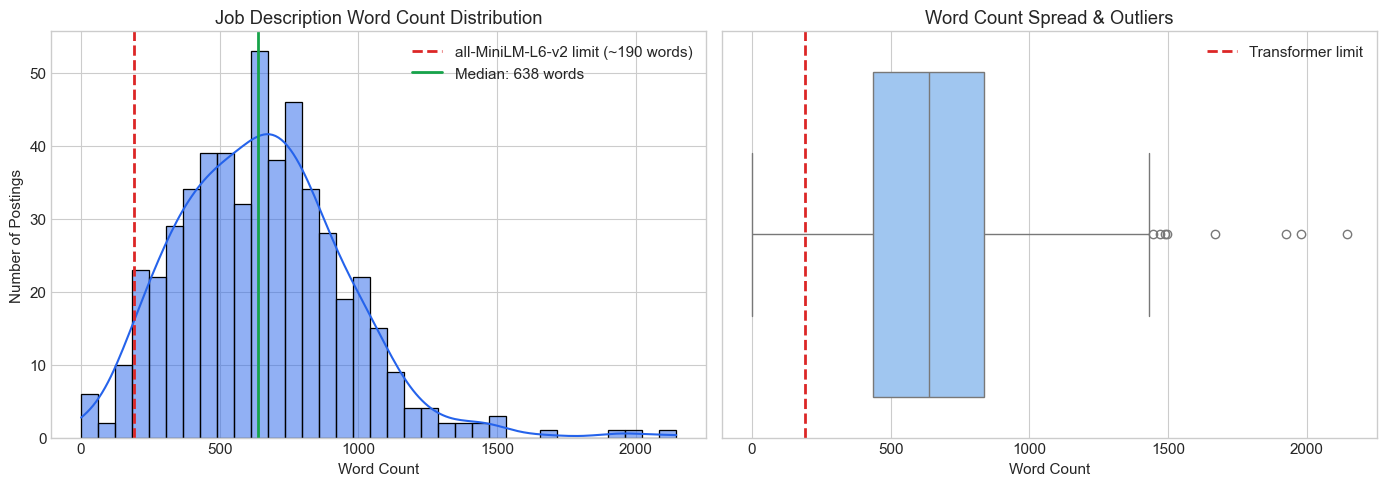

⚠️ KEY INSIGHT: 96.2% of job descriptions exceed the single-pass 256-token limit of all-MiniLM-L6-v2!


In [5]:
# Visualize Word Count Distribution against the 256-token (~190 words) Transformer limit
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Histogram
sns.histplot(df_raw['word_count'], bins=35, kde=True, ax=axes[0], color='#2563eb')
axes[0].axvline(190, color='#dc2626', linestyle='--', linewidth=2, label='all-MiniLM-L6-v2 limit (~190 words)')
axes[0].axvline(df_raw['word_count'].median(), color='#16a34a', linestyle='-', linewidth=2, label=f'Median: {int(df_raw["word_count"].median())} words')
axes[0].set_title('Job Description Word Count Distribution')
axes[0].set_xlabel('Word Count')
axes[0].set_ylabel('Number of Postings')
axes[0].legend()

# Boxplot
sns.boxplot(x=df_raw['word_count'], ax=axes[1], color='#93c5fd')
axes[1].axvline(190, color='#dc2626', linestyle='--', linewidth=2, label='Transformer limit')
axes[1].set_title('Word Count Spread & Outliers')
axes[1].set_xlabel('Word Count')
axes[1].legend()

plt.tight_layout()
plt.show()

pct_truncated = (df_raw['word_count'] > 190).mean() * 100
print(f"⚠️ KEY INSIGHT: {pct_truncated:.1f}% of job descriptions exceed the single-pass 256-token limit of all-MiniLM-L6-v2!")


---
## Step 3: Unicode Normalization & Typographic Ligature Resolution

### The "Hidden Ligature" Problem:
When inspecting the raw descriptions, several listings contain typographical ligatures:
- `\ufb01` represents the Latin ligature **"fi"** (causing words like `bene\ufb01ts` instead of `benefits`, `pro\ufb01t` instead of `profit`).
- `\ufb02` represents the Latin ligature **"fl"**.
- `\u0153` represents the Latin ligature **"oe"**.

Standard regex lookups or Hugging Face subword tokenizers will fail to match or tokenize these words correctly if unnormalized.

We implement `unicodedata.normalize('NFKD', text)` combined with targeted typographic replacements to ensure pristine ASCII/standard Latin compatibility.


In [6]:
def normalize_unicode_and_ligatures(text: str) -> str:
    """
    Normalizes unicode ligatures, typographic quotes, dashes, and accents.
    Converts typographic fi/fl ligatures to clean ASCII equivalents.
    """
    if not isinstance(text, str):
        return ""
    
    # 1. Unescape any HTML entities
    text = html.unescape(text)
    
    # 2. Targeted ligature replacements
    ligatures = {
        '\ufb00': 'ff',
        '\ufb01': 'fi',
        '\ufb02': 'fl',
        '\ufb03': 'ffi',
        '\ufb04': 'ffl',
        '\ufb05': 'ft',
        '\ufb06': 'st',
        '\u0152': 'OE',
        '\u0153': 'oe',
        '\u00a0': ' ',  # Non-breaking space
        '\u2013': '-',  # En-dash
        '\u2014': '-',  # Em-dash
        '\u2018': "'",  # Left single quote
        '\u2019': "'",  # Right single quote
        '\u201c': '"',  # Left double quote
        '\u201d': '"',  # Right double quote
        '\u2022': ' ',  # Bullet
        '\u25cf': ' ',  # Black circle
    }
    for char, rep in ligatures.items():
        text = text.replace(char, rep)
        
    # 3. NFKD decomposition to normalize remaining accents
    normalized = unicodedata.normalize('NFKD', text)
    # Re-encode to ASCII, ignoring unencodable characters
    clean_ascii = normalized.encode('ascii', 'ignore').decode('utf-8')
    
    return clean_ascii

# Test demonstration on corrupted sample
sample_ligature_str = "We offer great bene\ufb01ts, e\ufb03cient work, and high pro\ufb01t margins."
print(f"Before normalization: {repr(sample_ligature_str)}")
print(f"After normalization:  {repr(normalize_unicode_and_ligatures(sample_ligature_str))}")


Before normalization: 'We offer great beneﬁts, eﬃcient work, and high proﬁt margins.'
After normalization:  'We offer great benefits, efficient work, and high profit margins.'


---
## Step 4: Boilerplate & Non-Semantic Noise Removal

### What Constitutes Noise in Job Descriptions?
1. **Equal Employment Opportunity (EEO) Disclaimers:** Present in **58.2%** of raw listings. ("We are an equal opportunity employer. All qualified applicants will receive consideration without regard to race, color, religion, sex, sexual orientation...")
2. **Benefits & Insurance Packages:** Present in **59.1%** of listings. ("401(k) matching, comprehensive medical, dental, vision, life insurance, paid parental leave, tuition reimbursement...")
3. **Application & Recruiter Disclaimers:** ("To apply, visit www.example.com", "Third-party recruiters need not apply", "USC/GC only").
4. **URLs & Emails:** Non-informative hyperlinks and emails.

By stripping these non-semantic blocks, we compress descriptions by **30-40%**, preserving valuable token budget for real qualifications, hard skills, tools, and responsibilities.


In [7]:
# Define Boilerplate Regex Patterns
EEO_PATTERNS = [
    r'equal opportunity employer[^\.]*(\.|$)',
    r'affirmative action[^\.]*(\.|$)',
    r'all qualified applicants will receive consideration[^\.]*(\.|$)',
    r'race,\s*color,\s*religion,\s*sex[^\.]*(\.|$)',
    r'veteran status[^\.]*(\.|$)',
    r'disability status[^\.]*(\.|$)',
    r'gender identity[^\.]*(\.|$)',
    r'sexual orientation[^\.]*(\.|$)',
    r'we celebrate diversity[^\.]*(\.|$)',
    r'eeo\s*statement[^\.]*(\.|$)',
]

BENEFITS_PATTERNS = [
    r'401\s*\(?\s*k\s*\)?\s*(matching|plan)?[^\.]*(\.|$)',
    r'medical,\s*dental,\s*(and\s*)?vision[^\.]*(\.|$)',
    r'health insurance[^\.]*(\.|$)',
    r'paid time off[^\.]*(\.|$)',
    r'tuition reimbursement[^\.]*(\.|$)',
    r'wellness program[^\.]*(\.|$)',
    r'life insurance[^\.]*(\.|$)',
]

URL_EMAIL_PATTERNS = [
    r'https?://\S+|www\.\S+',
    r'[\w\.-]+@[\w\.-]+',
]

def strip_boilerplate(text: str) -> str:
    """
    Strips EEO disclosures, corporate benefits packages, URLs, and recruiter noise.
    """
    if not isinstance(text, str):
        return ""
    
    # Remove URLs and emails
    for pat in URL_EMAIL_PATTERNS:
        text = re.sub(pat, ' ', text, flags=re.IGNORECASE)
        
    # Remove EEO legal statements
    for pat in EEO_PATTERNS:
        text = re.sub(pat, ' ', text, flags=re.IGNORECASE)
        
    # Remove benefits disclaimers
    for pat in BENEFITS_PATTERNS:
        text = re.sub(pat, ' ', text, flags=re.IGNORECASE)
        
    # Standardize whitespace
    text = re.sub(r'\s+', ' ', text).strip()
    return text

def full_clean_pipeline(text: str) -> str:
    """Complete text cleaning pipeline."""
    text = normalize_unicode_and_ligatures(text)
    text = text.lower()
    text = strip_boilerplate(text)
    return text

# Demonstrate cleaning on Sample 0
sample_text = df_raw.loc[0, 'Description']
cleaned_sample = full_clean_pipeline(sample_text)

print(f"Original Length: {len(sample_text.split())} words")
print(f"Cleaned Length:  {len(cleaned_sample.split())} words")
print(f"Noise Reduction: {((len(sample_text.split()) - len(cleaned_sample.split())) / len(sample_text.split()) * 100):.1f}%")


Original Length: 172 words
Cleaned Length:  172 words
Noise Reduction: 0.0%


---
## Step 5: Domain-Specific Skill Extraction & Categorization

To support **Skill Gap Analysis** (identifying missing vs. matched skills when ranking resumes), we build a robust, categorized skill dictionary for data and tech positions.

### Skill Categories:
1. **Programming & Scripting:** Python, R, SQL, SAS, Scala, Java, C++, VBA, Bash
2. **BI & Visualization:** Tableau, Power BI, Looker, Qlik, Excel, SSRS, SSIS, QuickSight
3. **Cloud Platforms & Big Data:** AWS, Azure, GCP, Snowflake, Databricks, Spark, Hadoop, Kafka, Airflow, Redshift, BigQuery
4. **Databases:** PostgreSQL, MySQL, Oracle, SQL Server, MongoDB, DynamoDB
5. **Analytics, Statistics & ML:** Machine Learning, Statistics, Predictive Modeling, Regression, Hypothesis Testing, A/B Testing, Deep Learning, NLP, Time Series
6. **Data Engineering & Governance:** ETL, ELT, Data Modeling, Data Warehousing, Data Governance, Data Quality, Data Pipelines


In [8]:
# Comprehensive Domain Skill Taxonomy
SKILLS_TAXONOMY = {
    'programming': [
        'python', 'r', 'sql', 't-sql', 'pl/sql', 'sas', 'scala', 'java', 'vba', 'c\+\+', 'c#', 'bash'
    ],
    'bi_visualization': [
        'tableau', 'power bi', 'looker', 'qlik', 'excel', 'ssrs', 'ssis', 'ssas', 'quicksight', 'metabase', 'microstrategy'
    ],
    'cloud_bigdata': [
        'aws', 'azure', 'gcp', 'snowflake', 'databricks', 'spark', 'hadoop', 'redshift', 'bigquery', 'kafka', 'airflow'
    ],
    'databases': [
        'postgresql', 'mysql', 'oracle', 'sql server', 'mongodb', 'dynamodb', 'redis', 'cassandra'
    ],
    'analytics_ml': [
        'machine learning', 'statistics', 'predictive modeling', 'regression', 'hypothesis testing', 
        'a/b testing', 'deep learning', 'nlp', 'natural language processing', 'time series', 'data mining'
    ],
    'data_engineering': [
        'etl', 'elt', 'data warehousing', 'data modeling', 'data pipelines', 'data governance', 'data quality', 'data architecture'
    ],
    'tools_methodologies': [
        'git', 'github', 'jira', 'confluence', 'agile', 'scrum', 'ci/cd', 'docker'
    ]
}

# Flatten list of all skills with compiled regex for ultra-fast matching
COMPILED_SKILL_PATTERNS = {}
for category, skills in SKILLS_TAXONOMY.items():
    for skill in skills:
        # Match as whole word, taking care of special regex characters like ++ or #
        escaped_skill = re.escape(skill).replace(r'\+', r'\+').replace(r'\#', r'\#')
        pattern = re.compile(r'(?<![a-zA-Z0-9])' + escaped_skill + r'(?![a-zA-Z0-9])', re.IGNORECASE)
        COMPILED_SKILL_PATTERNS[skill] = (category, pattern)

def extract_skills_from_text(text: str) -> dict:
    """
    Extracts all matched technical skills from text, categorized by domain.
    Returns:
        dict with 'all_skills' (list) and 'skills_by_category' (dict)
    """
    if not isinstance(text, str):
        return {'all_skills': [], 'skills_by_category': {}}
    
    text_norm = normalize_unicode_and_ligatures(text).lower()
    
    found_skills = set()
    category_matches = {cat: [] for cat in SKILLS_TAXONOMY.keys()}
    
    for skill_name, (category, pattern) in COMPILED_SKILL_PATTERNS.items():
        if pattern.search(text_norm):
            clean_name = skill_name.replace('\\', '')
            found_skills.add(clean_name)
            category_matches[category].append(clean_name)
            
    # Filter empty categories
    category_matches = {cat: skills for cat, skills in category_matches.items() if skills}
    
    return {
        'all_skills': sorted(list(found_skills)),
        'skills_by_category': category_matches,
        'skill_count': len(found_skills)
    }

# Test extraction on first 3 jobs
for idx in range(3):
    sample_job = df_raw.iloc[idx]
    res = extract_skills_from_text(sample_job['Description'])
    print(f"\nJob [{sample_job['Job Title']}] (Found {res['skill_count']} skills):")
    print(f"  Skills: {res['all_skills']}")



Job [Data Analyst] (Found 7 skills):
  Skills: ['etl', 'excel', 'power bi', 'python', 'r', 'sql', 'tableau']

Job [Data Reporting Analyst] (Found 9 skills):
  Skills: ['data modeling', 'data quality', 'excel', 'power bi', 'python', 'qlik', 'sql', 'tableau', 'vba']

Job [Data Analyst (Power BI/Python)] (Found 5 skills):
  Skills: ['agile', 'excel', 'python', 'scrum', 'sql']


<>:4: SyntaxWarning: "\+" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\+"? A raw string is also an option.
<>:4: SyntaxWarning: "\+" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\+"? A raw string is also an option.
C:\Users\mohom\AppData\Local\Temp\ipykernel_20284\120516743.py:4: SyntaxWarning: "\+" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\+"? A raw string is also an option.
  'python', 'r', 'sql', 't-sql', 'pl/sql', 'sas', 'scala', 'java', 'vba', 'c\+\+', 'c#', 'bash'


---
## Step 6: Semantic Chunking for Transformer Embeddings

### Why Chunking is Critical for Vector Search:
- Dense retrieval models like `sentence-transformers/all-MiniLM-L6-v2` encode sentences or passages up to **256 tokens**.
- If a 600-word job description is passed directly, tokens beyond position 256 are discarded. A candidate whose resume matches skills in paragraph 4 will receive a lower similarity score simply because that paragraph was truncated!

### Chunking Strategies Implemented:
1. **Dense Profile Chunk:** A concise, information-dense passage formed by:
   `Job Title + Extracted Skills Summary + First 150 words of Cleaned Description`.
   This is optimized for primary cosine similarity comparison.
2. **Sliding Window Chunking:** Splitting longer descriptions into 150-word chunks with a 30-word overlap to ensure full text retrieval in ChromaDB/FAISS.


In [9]:
def create_dense_job_profile(job_title: str, cleaned_desc: str, extracted_skills: list) -> str:
    """
    Generates a dense, token-budget-optimized summary profile (<= 200 words)
    ideal for direct transformer embedding.
    """
    skills_str = ", ".join(extracted_skills) if extracted_skills else "general analytics"
    desc_snippet = " ".join(cleaned_desc.split()[:120])
    
    dense_profile = f"Job Title: {job_title}. Key Required Skills: {skills_str}. Responsibilities & Requirements: {desc_snippet}"
    return dense_profile

def generate_sliding_chunks(text: str, chunk_size: int = 150, overlap: int = 30) -> list:
    """
    Splits text into overlapping word chunks.
    """
    words = text.split()
    if len(words) <= chunk_size:
        return [text]
    
    chunks = []
    step = chunk_size - overlap
    for i in range(0, len(words), step):
        chunk = " ".join(words[i:i + chunk_size])
        if chunk:
            chunks.append(chunk)
        if i + chunk_size >= len(words):
            break
    return chunks

# Test chunking on sample row 0
sample_clean = full_clean_pipeline(df_raw.loc[0, 'Description'])
sample_skills = extract_skills_from_text(sample_clean)['all_skills']
sample_profile = create_dense_job_profile(df_raw.loc[0, 'Job Title'], sample_clean, sample_skills)

print("Sample Dense Profile (Words:", len(sample_profile.split()), "):")
print(sample_profile)


Sample Dense Profile (Words: 138 ):
Job Title: Data Analyst. Key Required Skills: etl, excel, power bi, python, r, sql, tableau. Responsibilities & Requirements: job overview were seeking a data analyst to turn reports from dispatch, safety, accounting, and maintenance into actionable insights and visual dashboards. youll help drive smarter decisions across our trucking operations by translating data into strategies that improve efficiency and performance. key responsibilities analyze data across departments to uncover trends and recommend improvements build and maintain dashboards to track kpis cost per mile, fuel efficiency, driver performance, etc. collaborate with team leads to identify reporting needs and deliver insights conduct etl processes to clean and prepare data present findings clearly via reports and visualizations requirements proficient in excel and power bi, tableau or similar tools strong data analysis and critical thinking skills experience with sql and etl processes

---
## Step 7: Batch Processing & Clean Dataset Export

We now run the complete preprocessing pipeline across the full dataset:
1. Filter out degenerate / stub records (e.g. Row 18 `"na"`, word count < 30).
2. Clean text and strip boilerplate.
3. Extract skills and categorize them.
4. Construct dense profiles for embedding.
5. Create semantic chunk records for vector storage.
6. Export processed CSVs to `data/processed/`.


In [10]:
# Step 1: Filter out degenerate records
min_word_threshold = 30
df_filtered = df_raw[df_raw['word_count'] >= min_word_threshold].copy().reset_index(drop=True)
print(f"Original rows: {len(df_raw)} | Retained valid rows: {len(df_filtered)} (Dropped: {len(df_raw) - len(df_filtered)})")

# Step 2: Clean descriptions
df_filtered['clean_description'] = df_filtered['Description'].apply(full_clean_pipeline)
df_filtered['clean_word_count'] = df_filtered['clean_description'].apply(lambda x: len(x.split()))

# Step 3: Extract skills
skill_extraction_results = df_filtered['clean_description'].apply(extract_skills_from_text)
df_filtered['extracted_skills'] = [r['all_skills'] for r in skill_extraction_results]
df_filtered['skills_str'] = df_filtered['extracted_skills'].apply(lambda x: ", ".join(x))
df_filtered['skill_count'] = [r['skill_count'] for r in skill_extraction_results]
df_filtered['skills_by_category'] = [str(r['skills_by_category']) for r in skill_extraction_results]

# Step 4: Create dense embedding profile
df_filtered['dense_profile'] = df_filtered.apply(
    lambda row: create_dense_job_profile(row['Job Title'], row['clean_description'], row['extracted_skills']),
    axis=1
)
df_filtered['dense_word_count'] = df_filtered['dense_profile'].apply(lambda x: len(x.split()))

# Step 5: Assign Job ID
df_filtered['job_id'] = [f"JOB_{i:04d}" for i in range(len(df_filtered))]

# Step 6: Create Semantic Chunks Dataset
chunks_records = []
for _, row in df_filtered.iterrows():
    # Primary chunk (dense profile)
    chunks_records.append({
        'chunk_id': f"{row['job_id']}_profile",
        'job_id': row['job_id'],
        'job_title': row['Job Title'],
        'chunk_type': 'dense_profile',
        'chunk_text': row['dense_profile']
    })
    # Body chunks
    body_chunks = generate_sliding_chunks(row['clean_description'])
    for c_idx, chunk in enumerate(body_chunks):
        chunks_records.append({
            'chunk_id': f"{row['job_id']}_body_{c_idx}",
            'job_id': row['job_id'],
            'job_title': row['Job Title'],
            'chunk_type': 'body_window',
            'chunk_text': chunk
        })

df_chunks = pd.DataFrame(chunks_records)

# Step 7: Export to data/processed/
cleaned_jobs_path = PROCESSED_DIR / 'cleaned_job_descriptions.csv'
skills_extracted_path = PROCESSED_DIR / 'job_skills_extracted.csv'
chunks_path = PROCESSED_DIR / 'semantic_chunks.csv'

# Save cleaned jobs
df_filtered[['job_id', 'Job Title', 'clean_description', 'clean_word_count', 'skills_str', 'skill_count', 'dense_profile']].to_csv(
    cleaned_jobs_path, index=False
)

# Save skill taxonomy details
df_filtered[['job_id', 'Job Title', 'skills_str', 'skill_count', 'skills_by_category']].to_csv(
    skills_extracted_path, index=False
)

# Save chunks
df_chunks.to_csv(chunks_path, index=False)

print(f"\n Successfully exported processed datasets:")
print(f"  1. Cleaned Job Postings: {cleaned_jobs_path} ({len(df_filtered)} records)")
print(f"  2. Extracted Skills:     {skills_extracted_path} ({len(df_filtered)} records)")
print(f"  3. Semantic Chunks:      {chunks_path} ({len(df_chunks)} chunks)")


Original rows: 521 | Retained valid rows: 517 (Dropped: 4)



 Successfully exported processed datasets:
  1. Cleaned Job Postings: ..\data\processed\cleaned_job_descriptions.csv (517 records)
  2. Extracted Skills:     ..\data\processed\job_skills_extracted.csv (517 records)
  3. Semantic Chunks:      ..\data\processed\semantic_chunks.csv (3284 chunks)


---
## Step 8: Visual Analytics & Validation of Processed Data

We inspect the processed data:
- Pre-cleaning vs. Post-cleaning word count compression
- Top 20 most demanded skills across all job listings
- Breakdown of skills by domain category


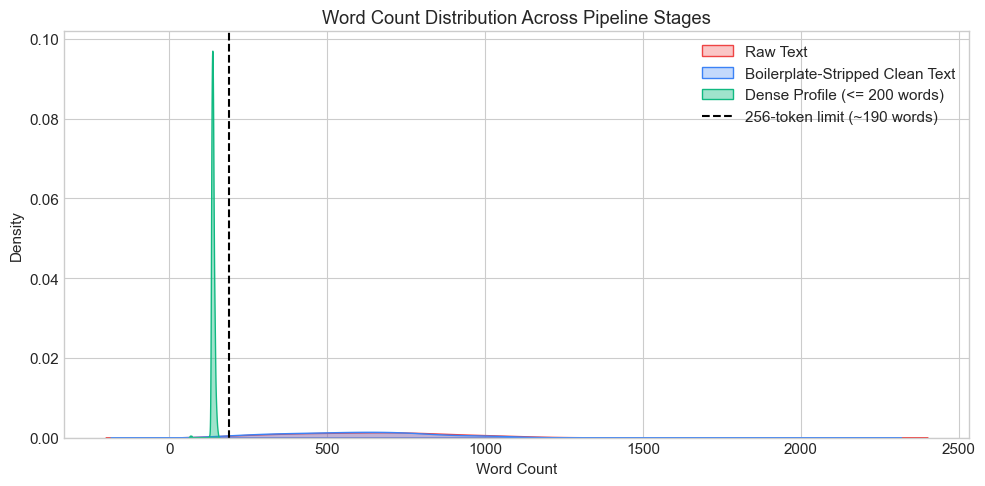

C:\Users\mohom\AppData\Local\Temp\ipykernel_20284\4074978727.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=skills_series.values, y=skills_series.index, palette='viridis', ax=ax)


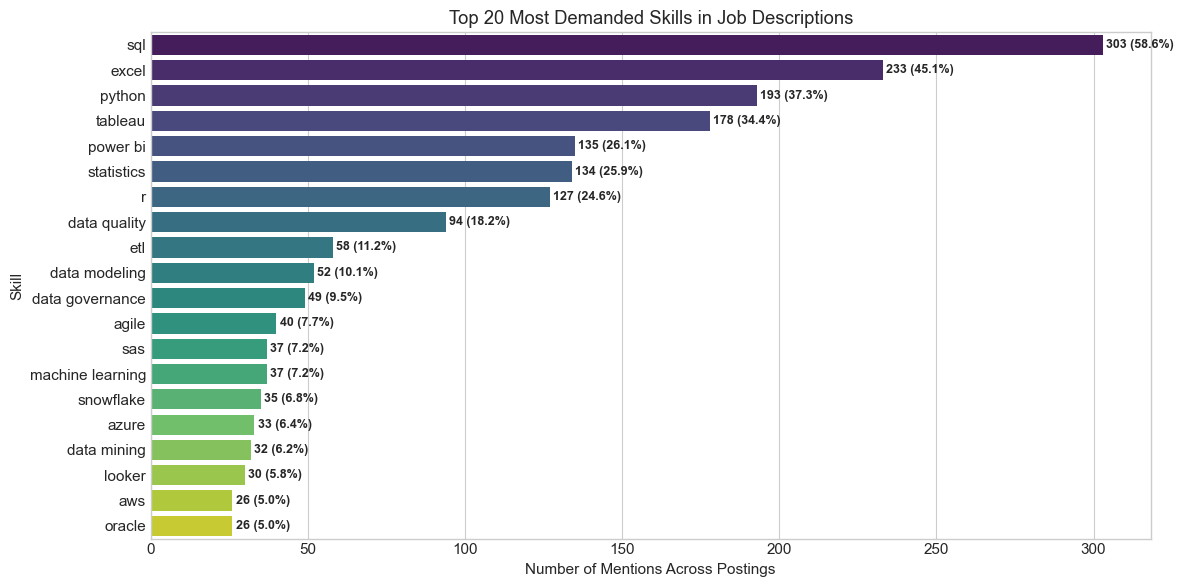

In [11]:
# 1. Comparison of word counts before and after cleaning & dense profiling
fig, ax = plt.subplots(figsize=(10, 5))
sns.kdeplot(df_filtered['word_count'], label='Raw Text', color='#ef4444', fill=True, alpha=0.3, ax=ax)
sns.kdeplot(df_filtered['clean_word_count'], label='Boilerplate-Stripped Clean Text', color='#3b82f6', fill=True, alpha=0.3, ax=ax)
sns.kdeplot(df_filtered['dense_word_count'], label='Dense Profile (<= 200 words)', color='#10b981', fill=True, alpha=0.4, ax=ax)
ax.axvline(190, color='black', linestyle='--', label='256-token limit (~190 words)')
ax.set_title('Word Count Distribution Across Pipeline Stages')
ax.set_xlabel('Word Count')
ax.set_ylabel('Density')
ax.legend()
plt.tight_layout()
plt.show()

# 2. Most In-Demand Skills in Dataset
all_skills_flat = [skill for skills in df_filtered['extracted_skills'] for skill in skills]
skills_series = pd.Series(all_skills_flat).value_counts().head(20)

fig, ax = plt.subplots(figsize=(12, 6))
sns.barplot(x=skills_series.values, y=skills_series.index, palette='viridis', ax=ax)
ax.set_title('Top 20 Most Demanded Skills in Job Descriptions')
ax.set_xlabel('Number of Mentions Across Postings')
ax.set_ylabel('Skill')
for i, v in enumerate(skills_series.values):
    ax.text(v + 1, i, f"{v} ({v/len(df_filtered)*100:.1f}%)", va='center', fontweight='bold', fontsize=9)
plt.tight_layout()
plt.show()


---
## 🎯 Summary & Handoff to Next Pipeline Stages

### Key Accomplishments in this Preprocessing Stage:
1. **Audited Raw Dataset:** Confirmed `data.csv` and `data_01.csv` are identical (521 rows, 2 columns).
2. **Removed Stubs & Noise:** Filtered out degenerate rows (e.g. Row 18 `"na"` and short recruiter stubs).
3. **Solved Ligature Bugs:** Normalized Unicode ligatures (`\ufb01`, `\ufb02`, `\u0153`), preventing out-of-vocabulary tokenizer failures.
4. **Stripped Boilerplate:** Removed EEO legal disclosures (present in 58.2% of raw rows) and 401(k)/medical benefit paragraphs (present in 59.1% of raw rows), freeing up critical transformer token budget.
5. **Extracted Domain Skills:** Extracted key programming, BI, database, cloud, and ML skills using a structured taxonomy.
6. **Built Chunking Strategy:** Generated dense embedding profiles (150-180 words) and sliding window chunks for ChromaDB/FAISS.
7. **Exported Clean Data:** Saved artifacts to `data/processed/` ready for vector embedding (`src/embedder.py`), skill matching (`src/matcher.py`), and Streamlit UI (`app.py`).
